In [3]:
#
#   routines                              
#                               
#   Functions shared by multiple scripts that post-process solutions created
#   using the 4A2 solver

# Import modules and functions
import sys
import numpy as np
import matplotlib.pyplot as plt 
import scipy.interpolate as interp

# Set default directory to save figures in, plot resolution and font sizes
plt.rcParams["savefig.directory"] = '.'; plt.rcParams['savefig.dpi'] = 600;
plt.rc('font',size=14); plt.rc('axes',titlesize=16); plt.rc('axes',labelsize=16)

################################################################################

def calc_secondary(av,b):
    # Calculate secondary flow variables that you will need to inspect during
    # your post-processing, save them into the block "b" dictionary alongside
    # mesh coordinates and primary flow variables.
    # INSERT

    return b

################################################################################

def cut_i(b,i):
    # Take a structured cut along an "i = const" line, this is done using Python
    # indexing that starts from 0
    
    # Loop over all variables in dict and extract at given i
    c = {}
    for var in b:
        if isinstance(b[var],np.ndarray):
            if i < np.shape(b[var])[0]:
                c[var] = np.squeeze(b[var][i,:])
        else:
            c[var] = b[var]

    # Store the projected lengths in the i-direction
    c['lx'] = b['lx_i'][i,:]; c['ly'] = b['ly_i'][i,:];

    return c

################################################################################

def cut_block(g,n):
    # Cut a single block from a multi-block definition with lists, n is
    # specified using Python indexing that starts from 0
    
    # Loop over all variables in dict and extract data at the block index
    b = {}
    for var in g:
        if isinstance(g[var],list):
            b[var] = np.squeeze(g[var][n])
        else:
            b[var] = g[var]

    return b

################################################################################

def area_av(c,prop):
    # Calculate area average of a property over the whole cut

    # Calculate total side length from two projected components
    l = (c['lx']**2 + c['ly']**2)**0.5

    # Area average of property
    p = np.sum(face_av(c[prop]) * l) / np.sum(l) 

    return p,l

################################################################################

def mass_av(c,prop):
    # Calculate mass average of a property over the whole cut

    # Calculate mass flow through each face
    mass = face_av(c['rovx']) * c['lx'] + face_av(c['rovy']) * c['ly'] 

    # Mass average of property
    p = np.sum(face_av(c[prop]) * mass) / np.sum(mass) 

    return p,mass

################################################################################

def face_av(p):
    # Calculate facet centred average of a value

    # Equal weighting of two nodes on a line
    p_av = 0.5 * (p[1:] + p[:-1])

    return p_av

################################################################################

def cell_av(p):
    # Calculate cell centred average of a value

    # Equal weighting of four nodes around a quad
    p_av = 0.25 * (p[1:,1:] + p[1:,:-1] + p[:-1,1:] + p[:-1,:-1])

    return p_av

################################################################################

def dist(x,y,scale=False,axis=-1):
    # Calculate dimensional or non-dimensional distance along a line

    # Calculate distance by Pythagoras
    ds = (np.diff(x,axis=axis) ** 2 + np.diff(y,axis=axis) ** 2) ** 0.5

    # Sum in the specified dimension, works on 1D or 2D arrays
    if ds.ndim == 1:
        s = np.concatenate([np.zeros(1),np.cumsum(ds,axis=axis)],axis=axis)
    else:
        s = np.concatenate([np.zeros([1,1]),np.cumsum(ds,axis=axis)],axis=axis)

    # Scale the output from 0 to 1
    if scale == True:
        if s.ndim == 1:
            s = s / s[-1]
        elif axis == 0:
            s = s / s[[-1],:]
        else:
            s = s / s[:,[-1]]

    return(s)

################################################################################

def norm(x,y):
    # Calculate normals to a line

    # Get normal direction from differences between points 
    n = np.stack([np.diff(y),-np.diff(x)]); 
   
    # Mid point averages of normals and add on end points
    n = np.concatenate([n[:,0].reshape([2,1]),
        0.5 * (n[:,:-1] + n[:,1:]),n[:,-1].reshape([2,1])],axis=1)

    # Normalise to unit length
    n = n / np.tile(np.sum(n**2,axis=0)**0.5,[2,1])
    
    # Split into components
    nx = n[0,:]; ny = n[1,:];
    
    return(nx,ny)

################################################################################

def polyspace(s_1,s_2,ds_1,ds_2,ni):
    # Polynomially spaced points

    # Use a cubic to determine points spacing to match values and deltas at ends
    p = np.polyfit([1,2,ni-1,ni],[s_1,s_1+ds_1,s_2-ds_2,s_2],3)
    x = np.arange(1,ni+1); s = np.polyval(p,x);
    s[0] = s_1; s[-1] = s_2;

    return(s)

################################################################################

def geospace(s_1,s_2,ds_1,ni):
    # Geometric progression spaced points with constant common ratio

    # Set limits on the common ratios to search
    r_min = 1e-5; r_max = 1e5; r_old = 1.0; r_tol = 1e-9;

    # Bisect common ratio until converged
    r = 0.5 * (r_min + r_max)
    while abs(r - r_old) > r_tol:
        
        # Evaluate the sum of the series
        S = ds_1 * (1 - r**(ni-1)) / (1 - r)
        
        # Check the sum and move the limits
        if S > abs(s_2 - s_1):
            r_max = r
        else:
            r_min = r
        
        # Update current ratio
        r_old = r; r = 0.5 * (r_min + r_max);
    
    # Generate the series and correct the final value
    s = s_1 + ds_1 * (1 - r**np.arange(ni)) / (1 - r)
    s = s * s_2 / s[-1]

    return(s)

################################################################################

def smooth_loop(x):
    # Smooth a loop of values with moving average

    # Repeat start and end values
    x = np.concatenate((x[-3:-1],x,x[1:3]))

    # 5 point average
    x = (x[0:-4] + x[1:-3] + x[2:-2] + x[3:-1] + x[4:]) / 5.0

    return x

################################################################################

def smooth(x):
    # Smooth a vector of values with moving average

    # 5 point average in the centre
    x[2:-2] = (x[0:-4] + x[1:-3] + x[2:-2] + x[3:-1] + x[4:]) / 5.0

    # 3 point average near the ends
    x[1] = (x[0] + x[1] + x[2]) / 3.0
    x[-2] = (x[-3] + x[-2] + x[-1]) / 3.0

    return x

################################################################################

def transfinite(x_i1,y_i1,x_j1,y_j1,x_i2,y_i2,x_j2,y_j2):
    # 2D transfinite interpolation to create coordinates internal to four curves

    # Ensure all inputs are 2D and correctly shaped
    x_i1 = np.reshape(x_i1,[1,-1]); y_i1 = np.reshape(y_i1,[1,-1]);
    x_i2 = np.reshape(x_i2,[1,-1]); y_i2 = np.reshape(y_i2,[1,-1]);
    x_j1 = np.reshape(x_j1,[-1,1]); y_j1 = np.reshape(y_j1,[-1,1]);
    x_j2 = np.reshape(x_j2,[-1,1]); y_j2 = np.reshape(y_j2,[-1,1]);

    # Distance along each curve
    s_i1 = dist(x_i1,y_i1,True,1); s_i2 = dist(x_i2,y_i2,True,1);  
    s_j1 = dist(x_j1,y_j1,True,0); s_j2 = dist(x_j2,y_j2,True,0);

    # Relative spacing throughout the surface in both directions
    u = ((1 - s_j1) * s_i1 + s_j1 * s_i2) / (1 - (s_i2 - s_i1) * (s_i2 - s_i1))
    v = ((1 - s_i1) * s_j1 + s_i1 * s_j2) / (1 - (s_j2 - s_j1) * (s_i2 - s_i1))

    # Generate internal coordinates by transfinite interpolation
    x = (1-v) * x_i1 + v * x_i2 + (1-u) * x_j1 + u * x_j2 - ( (1-u) * (1-v) * 
        x_i1[0,0] + u * v * x_i2[0,-1] + u * (1-v) * x_i1[0,-1] + (1-u) * v *
        x_i2[0,0] );
    y = (1-v) * y_i1 + v * y_i2 + (1-u) * y_j1 + u * y_j2 - ( (1-u) * (1-v) * 
        y_i1[0,0] + u * v * y_i2[0,-1] + u * (1-v) * y_i1[0,-1] + (1-u) * v *
        y_i2[0,0] );

    return x,y

################################################################################

def match(n_1,n_2,i_1,j_1,i_2,j_2):
    # Store block matching data in a dictionary, note all indices begin from 1
    # to be used in the Fortran solver
    
    # Initialise the dictionary
    p = {}

    # Store the block numbers
    p['n_1'] = n_1; p['n_2'] = n_2;

    # Make sure the lengths match and scalar values are repeated
    nk = np.max([i_1.size,i_2.size,j_1.size,j_2.size])
    i_1 = i_1 * np.ones(nk,dtype=int); i_2 = i_2 * np.ones(nk,dtype=int);
    j_1 = j_1 * np.ones(nk,dtype=int); j_2 = j_2 * np.ones(nk,dtype=int);

    # Store indices in the dictionary
    p['i_1'] = i_1; p['i_2'] = i_2; p['j_1'] = j_1; p['j_2'] = j_2; 

    # Store the length of the patch in the dictionary
    p['nk'] = nk

    return(p)

################################################################################

def mesh_aerofoil(geom,nj_c,ni_dom,nj_dom,ni_bc,d,dx):
    # Create a 5-block mesh around an aerofoil, one C-block and 4 H-blocks

    # Initialise the dictionary to store the mesh for each block in a list 
    g = {}; g['nn'] = 5;
    for var in ['x','y','ni','nj','match','n_in','n_out','wall']:
        g[var] = []; 

    # Join the suction and pressure surfaces together, starting at PS TE
    x_foil = np.concatenate([np.flip(geom['x_b']),geom['x_a'][1:]])
    y_foil = np.concatenate([np.flip(geom['y_b']),geom['y_a'][1:]])
    
    # Get the length of the C-block
    ni_c = np.size(x_foil) 

    # Create the wing C-block by offsetting j indices in the normal direction
    sj = d * np.reshape(geospace(0,1,0.5/float(nj_c),nj_c),[1,nj_c])
    dj_edge = np.diff(sj[0,-2:]); di_edge = np.diff(geom['x_a'][-2:]);
    nx,ny = norm(x_foil,y_foil) 
    g['x'].append(np.reshape(x_foil,[ni_c,1]) - np.reshape(nx,[ni_c,1]) * sj); 
    g['y'].append(np.reshape(y_foil,[ni_c,1]) - np.reshape(ny,[ni_c,1]) * sj);

    # Create H-block to join with lower domain boundary curve "c" from two "j =
    # const" curves
    x_j2 = np.flip(g['x'][0][:ni_dom,[-1]]) 
    y_j2 = np.flip(g['y'][0][:ni_dom,[-1]])
    sx = (x_j2 - x_j2[0]) / (x_j2[-1] - x_j2[0])
    x_j1 = sx * (x_j2[-1] + dx[1] - (x_j2[0] + dx[0])) + (x_j2[0] + dx[0])
    y_j1 = interp.pchip_interpolate(geom['x_c'],geom['y_c'],x_j1);
    dsj_2 = dj_edge / np.mean(y_j2 - y_j1)
    sj = np.flip(1 - geospace(0,1,dsj_2,nj_dom))
    g['x'].append((1-sj) * x_j1 + sj * x_j2)
    g['y'].append((1-sj) * y_j1 + sj * y_j2)
    
    # Create H-block to join with upper domain boundary curve "d" from two "j =
    # const curves", re-use boundary x-coordinates from before
    x_j2 = x_j1
    x_j1 = g['x'][0][-ni_dom:,[-1]]
    y_j1 = g['y'][0][-ni_dom:,[-1]]
    y_j2 = interp.pchip_interpolate(geom['x_d'],geom['y_d'],x_j2);
    dsj_1 = dj_edge / np.mean(y_j2 - y_j1) 
    sj = geospace(0,1,dsj_1,nj_dom)
    g['x'].append((1-sj) * x_j1 + sj * x_j2)
    g['y'].append((1-sj) * y_j1 + sj * y_j2)

    # Create H-block at the inlet from four curves bounding the block
    x_i2 = np.concatenate([g['x'][1][[0],:],
        np.reshape(g['x'][0][ni_dom:-ni_dom,[-1]],[1,-1]),
        g['x'][2][[0],:]],axis=1)
    y_i2 = np.concatenate([g['y'][1][[0],:],
        np.reshape(g['y'][0][ni_dom:-ni_dom,[-1]],[1,-1]),
        g['y'][2][[0],:]],axis=1)
    sj = np.reshape(np.linspace(0,1,np.shape(x_i2)[1]),[1,-1])
    x_i1 = geom['x_c'][0] * (1 - sj) + geom['x_d'][0] * sj
    y_i1 = geom['y_c'][0] * (1 - sj) + geom['y_d'][0] * sj
    dsi_2 = dj_edge / (np.mean(x_i2 - x_i1))
    si = np.flip(1 - geospace(0,1,dsi_2,ni_bc))
    x_j1 = x_i1[0,0] * (1 - si) + x_i2[0,0] * si
    y_j1 = interp.pchip_interpolate(geom['x_c'],geom['y_c'],x_j1)
    x_j2 = x_i1[0,-1] * (1 - si) + x_i2[0,-1] * si
    y_j2 = interp.pchip_interpolate(geom['x_d'],geom['y_d'],x_j2)
    x,y = transfinite(x_i1,y_i1,x_j1,y_j1,x_i2,y_i2,x_j2,y_j2)
    g['x'].append(x); g['y'].append(y)
    nj_in = sj.size;

    # Create H-block at the outlet from four curves bounding the block
    x_i1 = np.concatenate([g['x'][1][[-1],:], 
        np.flip(g['x'][0][[0],:-1],axis=1), g['x'][0][[-1],1:],
        g['x'][2][[-1],1:]],axis=1)
    y_i1 = np.concatenate([g['y'][1][[-1],:], 
        np.flip(g['y'][0][[0],:-1],axis=1), g['y'][0][[-1],1:],
        g['y'][2][[-1],1:]],axis=1)
    sj = np.reshape(np.linspace(0,1,np.shape(x_i1)[1]),[1,-1])
    x_i2 = geom['x_c'][-1] * (1 - sj) + geom['x_d'][-1] * sj
    y_i2 = geom['y_c'][-1] * (1 - sj) + geom['y_d'][-1] * sj
    dsi_1 = di_edge / np.mean(x_i2 - x_i1)
    si = geospace(0,1,dsi_1,ni_bc)
    x_j1 = x_i1[0,0] * (1 - si) + x_i2[0,0] * si
    y_j1 = interp.pchip_interpolate(geom['x_c'],geom['y_c'],x_j1)
    x_j2 = x_i1[0,-1] * (1 - si) + x_i2[0,-1] * si
    y_j2 = interp.pchip_interpolate(geom['x_d'],geom['y_d'],x_j2)
    x,y = transfinite(x_i1,y_i1,x_j1,y_j1,x_i2,y_i2,x_j2,y_j2)
    g['x'].append(x); g['y'].append(y)
    nj_out = sj.size;

    # Store the shape of all blocks
    for n in range(len(g['x'])):
        g['ni'].append(np.shape(g['x'][n])[0])
        g['nj'].append(np.shape(g['x'][n])[1])

    # Print the block sizes
    print('ni = ', g['ni']); print('nj = ', g['nj']);

    # Join the C-block to the lower domain H-block
    g['match'].append(match(1,2,np.arange(1,ni_dom+1),np.array(nj_c),
        np.arange(ni_dom,0,-1),np.array(nj_dom)))

    # Join the C-block to the upper domain H-block
    g['match'].append(match(1,3,np.arange(ni_c-ni_dom+1,ni_c+1),
        np.array(nj_c),np.arange(1,ni_dom+1),np.array(1)))

    # Join the C-block to the inlet H-block
    g['match'].append(match(1,4,np.arange(ni_dom,ni_c-ni_dom+2),np.array(nj_c),
        np.array(ni_bc),np.arange(nj_dom,nj_in-nj_dom+2)))

    # Join the C-block to the outlet H-block in two places
    g['match'].append(match(1,5,np.array(1),np.arange(1,nj_c+1),
        np.array(1),np.arange(nj_c+nj_dom-1,nj_dom-1,-1)))
    g['match'].append(match(1,5,np.array(ni_c),np.arange(1,nj_c+1),
        np.array(1),np.arange(nj_dom+nj_c-1,nj_dom+2*nj_c-1)))

    # Join all of the domain blocks together in four places
    g['match'].append(match(4,2,np.array(ni_bc),np.arange(1,nj_dom+1),
        np.array(1),np.arange(1,nj_dom+1)))
    g['match'].append(match(5,2,np.array(1),np.arange(1,nj_dom+1),
        np.array(ni_dom),np.arange(1,nj_dom+1)))
    g['match'].append(match(4,3,np.array(ni_bc),
        np.arange(nj_in-nj_dom+1,nj_in+1),np.array(1),np.arange(1,nj_dom+1)))
    g['match'].append(match(5,3,np.array(1),np.arange(nj_out-nj_dom+1,nj_out+1),
        np.array(ni_dom),np.arange(1,nj_dom+1)))

    # Number of matching patches
    g['nm'] = len(g['match'])

    # Specify which blocks the inlet and outlet patches lie on
    g['n_in'] = 4; g['n_out'] = 5;

    return(g)

################################################################################

def elliptic_smooth(g,nsteps):
    # Elliptic smoothing of a multi-block mesh

    # Loop over all iterations and all blocks
    for nstep in range(nsteps):
        for n in range(g['nn']):

            # Assemble the coordinates into a 3D array
            xy = np.stack([g['x'][n],g['y'][n]],axis=2)

            # Add halo cells where possible
            
            
            # Extract values from the interior offset in each direction
            xy_j2 = xy[1:-1,2:,:]; xy_i2 = xy[2:,1:-1,:];
            xy_j1 = xy[1:-1,0:-2,:]; xy_i1 = xy[0:-2,1:-1,:];
    
            # Calculate derivatives
            dxy_j = 0.5 * (xy_j2 - xy_j1) 
            dxy_i = 0.5 * (xy_i2 - xy_i1)
            dxy_corn = 0.25 * (xy[2:,2:,:] - xy[0:-2,2:,:] - xy[2:,0:-2,:] + 
                xy[0:-2,0:-2,:])
    
            # Calculate coefficients
            a = np.expand_dims(np.sum(dxy_i**2,axis=2)**0.5,axis=2)
            b = np.expand_dims(np.sum(dxy_i * dxy_j,axis=2),axis=2)
            c = np.expand_dims(np.sum(dxy_j**2,axis=2)**0.5,axis=2)

            # Solve and update the new interior mesh coordinates
            xy_new = (a * (xy_j2 + xy_j1) + c * (xy_i2 + xy_i1) - 
                2 * b * dxy_corn) / (2 * (a + c));
            g['x'][n][1:-1,1:-1] = xy_new[:,:,0]
            g['y'][n][1:-1,1:-1] = xy_new[:,:,1]

    return(g)

################################################################################

def gen_cols():
    # Generate array for colourmap of lines

    # RGB values
    cols = np.array([[0,0.447,0.741], [0.85,0.325,0.098], [0.929,0.694,0.125],
            [0.494,0.184,0.556], [0.466,0.674,0.188], [0.301,0.745,0.933],
            [0.635,0.078,0.184], [0.1,0.1,0.1], [0.6,0.6,0.6],])
    cols = np.tile(cols,[2,1])

    return(cols)

################################################################################

def colorbar(mappable,name):
    # Generate a colorbar of the correct height

    # Import extra matplotlib toolkit
    from mpl_toolkits.axes_grid1 import make_axes_locatable

    # Parse the input to get both axes and figure handles
    ax = mappable.axes
    fig = ax.figure

    # Check the size of the axes to place the colorbar on the long edge
    xlim = ax.get_xlim(); ylim = ax.get_ylim();
    if ylim[1] - ylim[0] > xlim[1] - xlim[0]:
        loc = 'right'; angle = 270; ori = 'vertical'; 
    else:
        loc = 'bottom'; angle = 0; ori = 'horizontal';

    # Create new axes for the colorbar
    divider = make_axes_locatable(ax)
    cax = divider.append_axes(loc,size="5%",pad=0.05)
    cbar = fig.colorbar(mappable,cax=cax,orientation=ori)
    
    # Add the title
    if loc == 'bottom':
        cbar.ax.set_xlabel(name,rotation=angle,labelpad=5)
    else:
        cbar.ax.set_ylabel(name,rotation=angle,labelpad=15)

    # Remove the offset
    cbar.formatter.set_useOffset(False)
    cbar.update_ticks()

    return cbar

################################################################################

def plot_bound(ax,b):
    # Plot the bounding lines of a block

    # Draw the "j = 1" and "j = nj" lines
    ax.plot(b['x'][:,[0,-1]],b['y'][:,[0,-1]],color=[0,0,0],linewidth=0.5)

    # Draw the "i = 1" and "i = ni" lines
    ax.plot(np.transpose(b['x'][[0,-1],:]),np.transpose(b['y'][[0,-1],:]),
        color=[0,0,0],linewidth=0.5)

    # Increase axis limits slightly to see the lines
    x_min, x_max, y_min, y_max = ax.axis()
    d = 0.001 * (x_max - x_min)
    ax.axis([x_min-d,x_max+d,y_min-d,y_max+d])

################################################################################

def plot_wall(ax,b,scale=True):
    # Plot the walls of a block
    
    # Set x-coordinates and y-coordinates that are not on walls as NaNs
    x = b['x'].copy(); y = b['y'].copy(); 
    x[b['wall'] == False] = float('nan'); y[b['wall'] == False] = float('nan');

    # Delete whole rows of data that are not on walls in the j-direction
    x_j = np.delete(x,np.all(b['wall'] == 0,axis=0),axis=1)
    y_j = np.delete(y,np.all(b['wall'] == 0,axis=0),axis=1)
    
    # Plot the walls on "j = const" lines 
    ax.plot(x_j,y_j,color=[0,0,0],linewidth=1)

    # Delete whole columns of data that are not on walls in the i-direction
    x_i = np.delete(x,np.all(b['wall'] == 0,axis=1),axis=0)
    y_i = np.delete(y,np.all(b['wall'] == 0,axis=1),axis=0)
    
    # Plot the walls on "i = const" lines 
    ax.plot(np.transpose(x_i),np.transpose(y_i),color=[0,0,0],linewidth=1)

    # Increase axis limits slightly to see the lines
    if scale == True:
        x_min, x_max, y_min, y_max = ax.axis()
        d = 0.001 * (x_max - x_min)
        ax.axis([x_min-d,x_max+d,y_min-d,y_max+d])

################################################################################

def read_settings(filename):
    # Read settings and boundary conditions from an input file

    # Initialise the dictionary to store the data
    av = {}

    # Open the file to read
    f = open(filename,'r')

    # Read the casename
    av['casename'] = f.readline()

    # Read two gas constants and calculate the rest
    av['gam'],av['rgas'] = [float(x) for x in f.readline().split()]
    av['cp'] = av['rgas'] * av['gam'] / (av['gam'] - 1.0)
    av['cv'] = av['cp'] / av['gam']

    # Read the CFL, smoothing factor and convergence limit
    av['cfl'],av['sfac'],av['d_max'] = [float(x) for x in f.readline().split()]

    # Read the number of steps
    av['nsteps'] = [int(x) for x in f.readline().split()]

    # Read the grid size
    av['ni'],av['nj'] = [int(x) for x in f.readline().split()]

    # Read the inlet boundary condition
    av['pstag'],av['tstag'],av['alpha'],av['rfin'] = \
        [float(x) for x in f.readline().split()]
 
    # Read the outlet boundary condition
    av['p'] = [float(x) for x in f.readline().split()]

    # Close the file 
    f.close()

    return(av)

################################################################################

def read_case(filename):
    # Read coordinates and flowfield from an output file

    # Determine the level of data included in the output file
    if 'coord' in filename:
        outtype = 1
    elif 'guess' in filename:
        outtype = 2
    elif 'final' in filename:
        outtype = 3

    # Initialise the dictionary to store the data
    g = {}

    # Open the file to read
    f = open(filename,'r')

    # Read the size of the mesh
    g['ni'] = np.fromfile(f,dtype=np.int32,count=1).item()
    g['nj'] = np.fromfile(f,dtype=np.int32,count=1).item()
    ni = g['ni']; nj = g['nj'];
    
    # Define the names and sizes of the mesh coordinate fields to read
    fieldnames = ['x','y','area','lx_i','ly_i','lx_j','ly_j']
    ni_mesh = np.array([0,0,-1,0,0,-1,-1]) + g['ni']
    nj_mesh = np.array([0,0,-1,-1,-1,0,0]) + g['nj']

    # Always read the mesh coordinates and projected lengths etc.
    for n,name in enumerate(fieldnames):

        # Read the data elementwise and keep 1D temporarily
        g[name] = np.fromfile(f,dtype=np.float32,count=ni_mesh[n]*nj_mesh[n]) 

        # Reshape the data into the correct numpy array shape, note Fortran
        # writes the data with the dimensions in the reverse order
        g[name] = np.reshape(g[name],[ni_mesh[n],nj_mesh[n]],order='F')

    # Always read the logical array describing the wall position
    g['wall'] = np.fromfile(f,dtype=np.int32,count=ni*nj) == 1
    g['wall'] = np.reshape(g['wall'],[ni,nj],order='F')

    # Read the flowfield data if written as an initial guess or full solution
    if outtype > 1:
        fieldnames = ['ro','roe','rovx','rovy']
        for n,name in enumerate(fieldnames):
            g[name] = np.fromfile(f,dtype=np.float32,count=ni*nj)
            g[name] = np.reshape(g[name],[ni,nj],order='F')

    # Read the cell increment only if the file is a full solution
    if outtype > 2:
        fieldnames = ['dro','droe','drovx','drovy']
        ni = g['ni']-1; nj = g['nj']-1;
        for n,name in enumerate(fieldnames):
            g[name] = np.fromfile(f,dtype=np.float32,count=ni*nj)
            g[name] = np.reshape(g[name],[ni,nj],order='F')

    # Close the file
    f.close()

    return(g)
   
################################################################################

def read_conv(filename):
    # Read residuals from a convergence log file

    # Initialise the dictionary to store the data
    l = {}

    # Read the entire file into a single array
    arr = np.loadtxt(filename)

    # Store the columns in the log dictionary
    fieldnames = ['nstep', 'dro_avg', 'droe_avg', 'drovx_avg', 'drovy_avg', 
        'dro_max', 'droe_max', 'drovx_max', 'drovy_max']
    for n,name in enumerate(fieldnames):
        l[name] = arr[:,n]

    return(l)

################################################################################

def default_settings(casename):
    # Create default settings and boundary conditions for a new case

    # Initialise the dictionary to store the data
    av = {}

    # Read the casename
    av['casename'] = casename

    # Gas constants
    av['rgas'] = 287; av['gam'] = 1.4

    # CFL, smoothing factor and convergence limit
    av['cfl'] = 0.4; av['sfac'] = 0.5; av['d_max'] = 0.0001;

    # Number of steps
    av['nsteps'] = 5000; 

    # Grid size
    av['ni'] = 53; av['nj'] = 37;

    # Inlet boundary condition
    av['pstag'] = 100000; av['tstag'] = 300; av['alpha'] = 0; av['rfin'] = 0.25;
 
    # Outlet boundary condition
    av['p'] = 75000;

    return(av)

################################################################################

def write_settings(av):
    # Create an input file with settings and boundary conditions

    # Open the file to write
    filename = 'input_' + av['casename'] + '.txt'
    f = open(filename,'w')

    # Write the casename
    f.write('%s\n' % av['casename'])

    # Write two gas constants
    f.write('%f %f\n' % (av['gam'],av['rgas']))

    # Write the CFL, smoothing factor and convergence limit
    f.write('%f %f %f\n' % (av['cfl'],av['sfac'],av['d_max']))

    # Write the number of steps
    f.write('%d\n' % (av['nsteps']))

    # Write the grid size
    f.write('%d %d\n' % (av['ni'],av['nj']))

    # Write the inlet boundary condition
    f.write('%f %f %f %f\n' % (av['pstag'],av['tstag'],av['alpha'],av['rfin']))
 
    # Write the outlet boundary condition
    f.write('%f\n' % (av['p']))

    # Close the file 
    f.close()

    return

################################################################################

def write_geom(av,geom):
    # Create an input file with settings and boundary conditions

    # Open the file to write
    filename = 'geom_' + av['casename'] + '.txt'
    f = open(filename,'w')

    # Write each curve in turn
    curvnames = ['a','b']
    for name in curvnames:
        if geom['x_' + name].ndim == 1:
        
            # Write the length of the curve
            f.write('%d\n' % np.size(geom['x_' + name]))

            # Assemble the x and y-coordinates into a single array
            xy = np.stack((geom['x_' + name],geom['y_' + name]),axis=1)
 
            # Write the coordinates with one pair of x and y-values on a line
            np.savetxt(f,xy,fmt='%13.8f')

    # Close the file 
    f.close()

    return

################################################################################

def write_mesh(av,g):
    # Write grid coordinates and connectivity data to file directly

    # Open the file to write
    filename = 'mesh_' + av['casename'] + '.bin'
    f = open(filename,'w')

    # Write the number of blocks
    np.array(g['nn']).astype(np.int32).tofile(f)

    # Loop over every block
    for n in range(g['nn']):

        # Write the size of the block and number of matching patches
        np.array([g['ni'][n],g['nj'][n]]).astype(np.int32).tofile(f)
    
        # Write the mesh coordinates, note these must be transposed to force
        # them to be written in Fortran dimension order
        g['x'][n].astype(np.float32).transpose().tofile(f)
        g['y'][n].astype(np.float32).transpose().tofile(f)

        # Write the wall position array
        g['wall'][n].astype(np.int32).transpose().tofile(f)

    # Write the blocks on which the inlet and outlets are located
    np.array([g['n_in'],g['n_out']]).astype(np.int32).tofile(f)

    # Write the number of matching patches
    np.array(g['nm']).astype(np.int32).tofile(f)

    # Loop over all patches
    for m in range(g['nm']):
        
        # Write the length of the patch and the two block numbers it joins
        p = g['match'][m]
        np.array([p['nk'],p['n_1'],p['n_2']]).astype(np.int32).tofile(f)
   
        # Write the index lists on both sides of the patch
        p['i_1'].astype(np.int32).tofile(f)
        p['j_1'].astype(np.int32).tofile(f)
        p['i_2'].astype(np.int32).tofile(f)
        p['j_2'].astype(np.int32).tofile(f)

    # Close the file 
    f.close()

    return

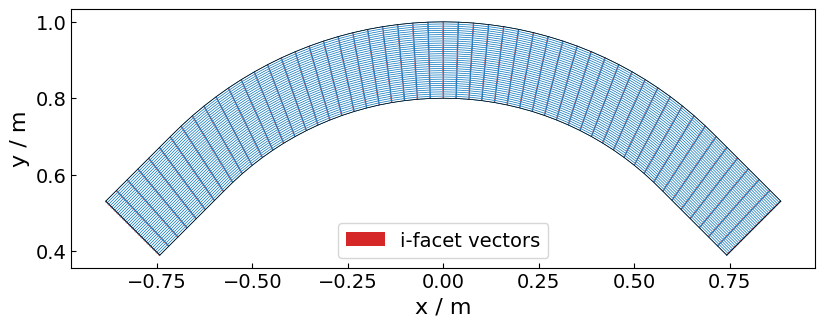

In [ ]:
#
#   plot_coord
#                               
#   Script to plot a mesh created using the 4A2 solver
#
#   Change to the directory you want to execute the script within and execute 
#   with "python path_to_script/plot_coord.py casename"

# Import modules and functions
import csv

def main():

    # Construct full filename to read the grid data
    filename = 'out_coord_bend.bin'

    # Read the case from file
    g = read_case(filename)

    # Read the edge-vector components and place each vector at its facet centre
    edge_vectors = {'i': ([], [], [], []), 'j': ([], [], [], [])}
    with open('mesh_edge_vectors.csv', newline='') as vector_file:
        reader = csv.DictReader(vector_file)
        for row in reader:
            i = int(row['i']) - 1
            j = int(row['j']) - 1
            if not (0 <= i < g['ni'] and 0 <= j < g['nj']):
                raise ValueError('Edge-vector indices do not match the mesh')

            if bool(row['lx_i']) != bool(row['ly_i']) or \
                    bool(row['lx_j']) != bool(row['ly_j']):
                raise ValueError('Each edge vector must have both components')

            if row['lx_i'] and row['ly_i']:
                x, y, u, v = edge_vectors['i']
                x.append((g['x'][i, j] + g['x'][i, j + 1]) / 2)
                y.append((g['y'][i, j] + g['y'][i, j + 1]) / 2)
                u.append(float(row['lx_i']))
                v.append(float(row['ly_i']))

            if row['lx_j'] and row['ly_j']:
                x, y, u, v = edge_vectors['j']
                x.append((g['x'][i, j] + g['x'][i + 1, j]) / 2)
                y.append((g['y'][i, j] + g['y'][i + 1, j]) / 2)
                u.append(float(row['lx_j']))
                v.append(float(row['ly_j']))

    # Open figure window and set the axes to be equal
    plt.figure(figsize=[9.6,7.2]); ax = plt.axes(); cols = gen_cols();
    ax.set_xlabel('x / m'); ax.set_ylabel('y / m');
    ax.set_aspect('equal',adjustable='box'); ax.tick_params(direction='in')

    # Plot the mesh coordinates to show the cells
    ax.plot(g['x'],g['y'],color=cols[0,:],linewidth=0.5)
    ax.plot(np.transpose(g['x']),np.transpose(g['y']),color=cols[0,:],
        linewidth=0.5)

    # Draw the boundary of the block
    plot_bound(ax,g)

    # Overlay the edge vectors at the centres of their corresponding facets
    for label, (x, y, u, v), color in (
        ('i-facet vectors', edge_vectors['i'], 'tab:red'),
        ('j-facet vectors', edge_vectors['j'], 'tab:orange'),
    ):
        ax.quiver(x, y, u, v, color=color, angles='xy', scale_units='xy',
            scale=1, pivot='mid', width=0.002, label=label)
    ax.legend()

    # Show all the plots
    plt.show()

    
main()
